<a href="https://colab.research.google.com/github/EmiiFernandez/actividades_data_sciente_ypf/blob/main/notebook/C30_Notebook-34.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

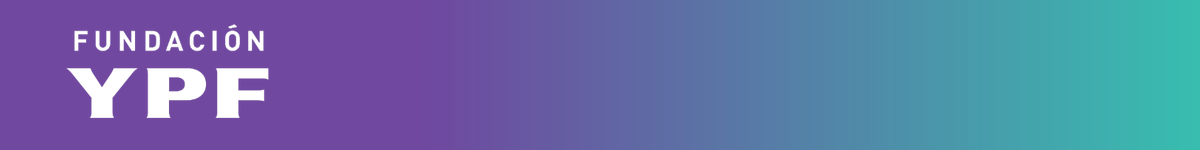

# Fundación YPF - Data Science

## Notebook 34: Monitoreo de modelos en producción (parte II): drift, PSI y reentrenamiento

### Índice de partes

* **Parte 0:** Preparación del entorno
* **Parte 1:** Repaso: pipeline en producción y data drift con el test K-S (clase 29)
* **Parte 2:** Model drift, data drift y concept drift
* **Parte 3:** Detectamos data drift con el Population Stability Index (PSI)
* **Parte 4:** Concept drift y alertas: armamos un panel de monitoreo
* **Parte 5:** Reentrenamiento y comparación de versiones del modelo
* **Parte 6:** Ejercicio para las salas de Zoom


## Parte 0: Preparación del entorno

En la clase anterior (Notebook 33) pusimos en producción el `MLPClassifier` entrenado sobre `cancer_mamario.csv` (Notebooks 29 a 32): armamos un `Pipeline` de sklearn, simulamos la llegada de pacientes nuevas en lotes y detectamos data drift con el test de Kolmogorov-Smirnov (K-S). Hoy retomamos exactamente ese mismo pipeline y esos mismos lotes para profundizar: sumamos una segunda técnica de detección de data drift (el Population Stability Index), diferenciamos data drift de concept drift, armamos un panel de alertas, y comparamos dos estrategias de reentrenamiento (por tiempo y aprendizaje online).

**Datasets:**

* `cancer_mamario.csv`: el mismo de las Notebooks 29 a 33. Lo usamos en la parte guiada.
* `venta_autos.csv`: publicaciones de autos usados con fecha real de publicación (el mismo de la Notebook 28 y de la Notebook 33). Lo usamos en el ejercicio de las salas, donde los lotes de tiempo ya no son una simulación: son semanas reales.

Antes de ejecutar, subí los archivos `cancer_mamario.csv` y `venta_autos.csv` al panel de archivos de Colab (ícono de carpeta a la izquierda).


In [ ]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")

import copy
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from scipy.stats import ks_2samp

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42


## Parte 1: Repaso: pipeline en producción y data drift con el test K-S (clase 29)

Reconstruimos en pocas celdas lo que armamos la clase pasada: el mismo preprocesamiento, la misma arquitectura de red (dos capas ocultas de 16 y 8 neuronas, ReLU) empaquetada en un `Pipeline`, los mismos 4 lotes simulando la llegada de pacientes en producción, y el mismo test K-S sobre `deg-malig`. Al usar el mismo `RANDOM_STATE` y el mismo split, los números coinciden con los de la Notebook 33.


In [ ]:
if not os.path.exists("cancer_mamario.csv"):
    from google.colab import files
    files.upload()

cancer = pd.read_csv("cancer_mamario.csv")

filas_antes = len(cancer)
cancer_limpio = cancer[(cancer != "?").all(axis=1)].copy()
print(f"Filas antes de sacar los '?': {filas_antes}. Filas despues: {len(cancer_limpio)}")

cancer_limpio["target"] = (cancer_limpio["class"] == "recurrence-events").astype(int)

columnas_categoricas = ["age", "menopause", "tumor-size", "inv-nodes", "node-caps",
                         "breast", "breast-quad", "irradiat"]
X = pd.get_dummies(cancer_limpio[columnas_categoricas + ["deg-malig"]], columns=columnas_categoricas)
y = cancer_limpio["target"]
print("Features despues del one-hot encoding:", X.shape[1])


Filas antes de sacar los '?': 286. Filas despues: 277
Features despues del one-hot encoding: 39


In [ ]:
X_train, X_prod, y_train, y_prod = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)

pipeline_modelo = Pipeline([
    ("escalado", StandardScaler()),
    ("mlp", MLPClassifier(
        hidden_layer_sizes=(16, 8),
        activation="relu",
        solver="adam",
        max_iter=1000,
        random_state=RANDOM_STATE,
    )),
])
pipeline_modelo.fit(X_train, y_train)

print("Entrenamiento:", X_train.shape, "Reservado para produccion:", X_prod.shape)
print(f"Iteraciones hasta converger: {pipeline_modelo.named_steps['mlp'].n_iter_}")


Entrenamiento: (207, 39) Reservado para produccion: (70, 39)
Iteraciones hasta converger: 664


In [ ]:
N_LOTES = 4
lotes_X = np.array_split(X_prod, N_LOTES)
lotes_y = np.array_split(y_prod, N_LOTES)

metricas_lotes = []
for i, (lote_x, lote_y) in enumerate(zip(lotes_X, lotes_y)):
    pred = pipeline_modelo.predict(lote_x)
    metricas_lotes.append({
        "lote": i,
        "n_pacientes": len(lote_x),
        "exactitud": accuracy_score(lote_y, pred),
        "f1_recurrencia": f1_score(lote_y, pred, pos_label=1, zero_division=0),
    })

metricas_df = pd.DataFrame(metricas_lotes)
metricas_df


,lote,n_pacientes,exactitud,f1_recurrencia
0,0,18,0.777778,0.666667
1,1,18,0.666667,0.400000
2,2,17,0.588235,0.363636
3,3,17,0.764706,0.333333


In [ ]:
media_train = X_train["deg-malig"].mean()
desvio_train = X_train["deg-malig"].std()
print(f"Entrenamiento - deg-malig: media {media_train:.2f}, desvio {desvio_train:.2f}")

resultados_drift = []
for i, lote_x in enumerate(lotes_X):
    estadistico, p_valor = ks_2samp(X_train["deg-malig"], lote_x["deg-malig"])
    resultados_drift.append({
        "lote": i,
        "media": lote_x["deg-malig"].mean(),
        "ks_estadistico": estadistico,
        "ks_p_valor": p_valor,
        "alerta_ks": p_valor < 0.05,
    })

drift_df = pd.DataFrame(resultados_drift)
drift_df


Entrenamiento - deg-malig: media 2.06, desvio 0.74


,lote,media,ks_estadistico,ks_p_valor,alerta_ks
0,0,2.222222,0.084541,0.999022,False
1,1,2.111111,0.079710,0.999633,False
2,2,2.000000,0.127877,0.928953,False
3,3,1.882353,0.106564,0.984253,False


Igual que en la Notebook 33: el desempeño varía de lote a lote por el tamaño chico de cada uno (ruido estadístico), y el test K-S no encuentra evidencia de data drift en ninguno de los 4 lotes (todos los p-valores superan ampliamente 0.05): tiene sentido, porque estos lotes salen del mismo dataset que el entrenamiento. A continuación simulamos el mismo escenario de drift controlado de la clase pasada (un cambio externo que hace que el último lote tenga pacientes con mayor grado de malignidad), para tener un caso positivo con el que comparar las técnicas nuevas de hoy.


In [ ]:
lote_con_drift = lotes_X[-1].copy()
y_lote_con_drift = lotes_y[-1]

lote_con_drift["deg-malig"] = (lote_con_drift["deg-malig"] + 1).clip(upper=3)

estadistico_drift, p_valor_drift = ks_2samp(X_train["deg-malig"], lote_con_drift["deg-malig"])

pred_drift = pipeline_modelo.predict(lote_con_drift)
exactitud_drift = accuracy_score(y_lote_con_drift, pred_drift)
f1_drift = f1_score(y_lote_con_drift, pred_drift, pos_label=1, zero_division=0)

exactitud_original = metricas_df.loc[metricas_df["lote"] == N_LOTES - 1, "exactitud"].iloc[0]
f1_original = metricas_df.loc[metricas_df["lote"] == N_LOTES - 1, "f1_recurrencia"].iloc[0]

print(f"KS contra entrenamiento: estadistico {estadistico_drift:.3f}, p-valor {p_valor_drift:.4f}")
print(f"Exactitud con el lote modificado: {exactitud_drift:.3f} (era {exactitud_original:.3f} sin el drift)")
print(f"F1 (recurrencia) con el lote modificado: {f1_drift:.3f} (era {f1_original:.3f} sin el drift)")


KS contra entrenamiento: estadistico 0.343, p-valor 0.0375
Exactitud con el lote modificado: 0.647 (era 0.765 sin el drift)
F1 (recurrencia) con el lote modificado: 0.250 (era 0.333 sin el drift)


## Parte 2: Model drift, data drift y concept drift

En la teoría de hoy vimos que **model drift** (la caída del poder predictivo de un modelo con el tiempo) se divide en dos fenómenos:

* **Data drift:** cambian los datos que entran al modelo (su distribución), pero no cambia la relación entre esos datos y la variable a predecir. Es lo que acabamos de ver arriba: `deg-malig` cambió de distribución en el lote simulado.
* **Concept drift:** cambia la relación entre las variables de entrada y la variable a predecir, aunque la distribución de los datos de entrada no cambie. El modelo fue entrenado con una relación que ya no es la misma, así que sus predicciones se vuelven menos confiables aunque los datos de entrada luzcan iguales.

En producción no siempre sabemos de antemano cuál de los dos está ocurriendo: por eso monitoreamos ambos frentes con técnicas distintas. Para data drift, el test K-S que ya usamos y el PSI que vemos a continuación. Para concept drift, el monitoreo del desempeño del modelo en el tiempo (Parte 4).


## Parte 3: Detectamos data drift con el Population Stability Index (PSI)

El PSI compara la distribución de una variable en dos momentos (entrenamiento vs. producción) dividiéndola en bloques y comparando el porcentaje de observaciones en cada uno:

$$PSI = \sum_{i} (pct\_actual_i - pct\_entrenamiento_i) \times \ln\left(\frac{pct\_actual_i}{pct\_entrenamiento_i}\right)$$

Con variables continuas los bloques suelen ser deciles (10 bloques con la misma cantidad de datos de entrenamiento en cada uno). `deg-malig` es el grado de malignidad del tumor y solo toma 3 valores (1, 2 o 3), así que en vez de deciles usamos directamente cada valor como un bloque: es la misma idea, adaptada a una variable con pocas categorías. La función de abajo hace esa elección automáticamente según la cantidad de valores distintos que tenga la variable de entrenamiento.

Un PSI mayor a 0.2 se interpreta como un cambio significativo en la distribución (la misma referencia que vimos en la teoría).


In [ ]:
def calcular_psi(train, actual, bins=10):
    """PSI entre una serie de entrenamiento y una de produccion.
    Si la variable tiene pocos valores distintos, usa cada valor como bloque.
    Si no, arma 'bins' deciles a partir de los cuantiles de 'train'.
    """
    eps = 1e-4
    if train.nunique() <= bins:
        niveles = sorted(set(train.unique()) | set(actual.unique()))
        train_pct = train.value_counts(normalize=True).reindex(niveles, fill_value=0)
        actual_pct = actual.value_counts(normalize=True).reindex(niveles, fill_value=0)
    else:
        bordes = np.quantile(train, np.linspace(0, 1, bins + 1))
        bordes[0], bordes[-1] = -np.inf, np.inf
        bordes = np.unique(bordes)
        train_pct = pd.cut(train, bins=bordes).value_counts(normalize=True, sort=False)
        actual_pct = pd.cut(actual, bins=bordes).value_counts(normalize=True, sort=False)
    train_pct = train_pct.clip(lower=eps)
    actual_pct = actual_pct.clip(lower=eps)
    return float(((actual_pct - train_pct) * np.log(actual_pct / train_pct)).sum())

resultados_psi = []
for i, lote_x in enumerate(lotes_X):
    valor_psi = calcular_psi(X_train["deg-malig"], lote_x["deg-malig"])
    resultados_psi.append({"lote": i, "psi": valor_psi, "alerta_psi": valor_psi > 0.2})

psi_df = pd.DataFrame(resultados_psi)
psi_df


,lote,psi,alerta_psi
0,0,0.051931,False
1,1,0.056150,False
2,2,0.165175,False
3,3,0.059344,False


In [ ]:
psi_drift = calcular_psi(X_train["deg-malig"], lote_con_drift["deg-malig"])
print(f"PSI del lote con drift simulado: {psi_drift:.3f} (alerta: {psi_drift > 0.2})")


PSI del lote con drift simulado: 2.205 (alerta: True)


El PSI confirma lo mismo que el test K-S: en los 4 lotes originales no hay alerta (PSI bajo), pero en el lote con el drift simulado el PSI supera 0.2. Tener las dos técnicas es útil porque miden cosas distintas (K-S compara distribuciones completas con un test estadístico, PSI resume el cambio en un único número fácil de poner como umbral de alerta) y a veces conviene mirarlas juntas antes de decidir que hay un problema real.


## Parte 4: Concept drift y alertas: armamos un panel de monitoreo

El concept drift no se detecta mirando solo los datos de entrada (como hicimos con K-S y PSI): se detecta mirando si el desempeño del modelo cae cuando ya conocemos el resultado real (`model monitoring`, como vimos en la teoría). Armamos un panel único que junta las tres señales (K-S, PSI y caída de desempeño respecto del lote 0) para decidir si hay que investigar un lote.


In [ ]:
exactitud_base = metricas_df.loc[metricas_df["lote"] == 0, "exactitud"].iloc[0]
UMBRAL_CAIDA = 0.15

panel = metricas_df.merge(drift_df[["lote", "ks_p_valor", "alerta_ks"]], on="lote")
panel = panel.merge(psi_df, on="lote")
panel["caida_exactitud"] = exactitud_base - panel["exactitud"]
panel["alerta_desempeno"] = panel["caida_exactitud"] > UMBRAL_CAIDA
panel["alerta_general"] = panel["alerta_ks"] | panel["alerta_psi"] | panel["alerta_desempeno"]

fila_drift = {
    "lote": "3 (drift simulado)",
    "n_pacientes": len(lote_con_drift),
    "exactitud": exactitud_drift,
    "f1_recurrencia": f1_drift,
    "ks_p_valor": p_valor_drift,
    "alerta_ks": p_valor_drift < 0.05,
    "psi": psi_drift,
    "alerta_psi": psi_drift > 0.2,
    "caida_exactitud": exactitud_base - exactitud_drift,
}
fila_drift["alerta_desempeno"] = fila_drift["caida_exactitud"] > UMBRAL_CAIDA
fila_drift["alerta_general"] = fila_drift["alerta_ks"] or fila_drift["alerta_psi"] or fila_drift["alerta_desempeno"]

panel = pd.concat([panel, pd.DataFrame([fila_drift])], ignore_index=True)
panel


,lote,n_pacientes,exactitud,f1_recurrencia,ks_p_valor,alerta_ks,psi,alerta_psi,caida_exactitud,alerta_desempeno,alerta_general
0,0,18,0.777778,0.666667,0.999022,False,0.051931,False,0.000000,False,False
1,1,18,0.666667,0.400000,0.999633,False,0.056150,False,0.111111,False,False
2,2,17,0.588235,0.363636,0.928953,False,0.165175,False,0.189542,True,True
3,3,17,0.764706,0.333333,0.984253,False,0.059344,False,0.013072,False,False
4,3 (drift simulado),17,0.647059,0.250000,0.037512,True,2.205030,True,0.130719,False,True


El panel deja ver con claridad la diferencia: los 4 lotes originales no disparan ninguna alerta, y el lote con el drift simulado dispara las tres (K-S, PSI y caída de desempeño) al mismo tiempo. En un sistema real, esta sería la señal para pasar a la siguiente parte: decidir si reentrenamos el modelo y con qué estrategia.


## Parte 5: Reentrenamiento y comparación de versiones del modelo

Vimos en la teoría dos estrategias de reentrenamiento: una basada en tiempo (reentrenar desde cero con todos los datos acumulados, incluidos los nuevos, una vez que el desempeño cae por debajo de lo aceptable) y aprendizaje online (actualizar el modelo de a poco con cada lote nuevo, sin volver a entrenar desde cero). Para comparar versiones del modelo de forma justa necesitamos datos que ninguna versión haya visto: tomamos los lotes 0, 1 y 2 (los lotes originales que no se usaron para entrenar ni para reentrenar) y les aplicamos el mismo tipo de drift simulado que al lote 3. Los juntamos en un solo **lote futuro** de 53 pacientes (en vez de usar un solo lote de 17 o 18) para que la comparación entre versiones no dependa del ruido estadístico de un lote chico, el mismo problema que vimos en la Parte 1.


In [ ]:
lote_futuro_x = pd.concat([lotes_X[0], lotes_X[1], lotes_X[2]]).copy()
lote_futuro_y = pd.concat([lotes_y[0], lotes_y[1], lotes_y[2]])
lote_futuro_x["deg-malig"] = (lote_futuro_x["deg-malig"] + 1).clip(upper=3)
print("Tamano del lote futuro:", lote_futuro_x.shape[0])

# Version 1: el modelo original, sin reentrenar
pred_v1 = pipeline_modelo.predict(lote_futuro_x)
exactitud_v1 = accuracy_score(lote_futuro_y, pred_v1)
f1_v1 = f1_score(lote_futuro_y, pred_v1, pos_label=1, zero_division=0)
print(f"Version 1 (original) en el lote futuro: exactitud {exactitud_v1:.3f}, F1 {f1_v1:.3f}")


Tamano del lote futuro: 53
Version 1 (original) en el lote futuro: exactitud 0.585, F1 0.476


**Estrategia 1: reentrenamiento completo por tiempo.** Una vez que llega el diagnóstico real de las pacientes del lote 3 (el que disparó las alertas), lo sumamos al set de entrenamiento original y reentrenamos el pipeline completo desde cero.


In [ ]:
X_reentreno = pd.concat([X_train, lote_con_drift])
y_reentreno = pd.concat([y_train, y_lote_con_drift])

pipeline_v2_completo = clone(pipeline_modelo)
pipeline_v2_completo.fit(X_reentreno, y_reentreno)

pred_v2 = pipeline_v2_completo.predict(lote_futuro_x)
exactitud_v2 = accuracy_score(lote_futuro_y, pred_v2)
f1_v2 = f1_score(lote_futuro_y, pred_v2, pos_label=1, zero_division=0)
print(f"Version 2 (reentrenamiento completo) en el lote futuro: exactitud {exactitud_v2:.3f}, F1 {f1_v2:.3f}")


Version 2 (reentrenamiento completo) en el lote futuro: exactitud 0.566, F1 0.439


**Estrategia 2: aprendizaje online.** En vez de reentrenar desde cero, actualizamos los pesos de la misma red ya entrenada usando `partial_fit` solo con el lote nuevo. Es más barato computacionalmente (no vuelve a ver todo el set de entrenamiento), aunque un solo paso de `partial_fit` ajusta los pesos menos que un reentrenamiento completo.


In [ ]:
pipeline_v3_online = copy.deepcopy(pipeline_modelo)
lote_drift_escalado = pipeline_v3_online.named_steps["escalado"].transform(lote_con_drift)
pipeline_v3_online.named_steps["mlp"].partial_fit(lote_drift_escalado, y_lote_con_drift)

pred_v3 = pipeline_v3_online.predict(lote_futuro_x)
exactitud_v3 = accuracy_score(lote_futuro_y, pred_v3)
f1_v3 = f1_score(lote_futuro_y, pred_v3, pos_label=1, zero_division=0)
print(f"Version 3 (aprendizaje online) en el lote futuro: exactitud {exactitud_v3:.3f}, F1 {f1_v3:.3f}")


Version 3 (aprendizaje online) en el lote futuro: exactitud 0.585, F1 0.476


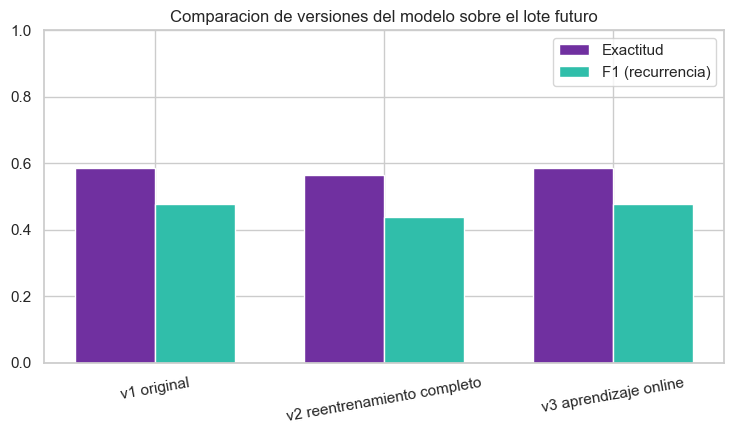

,version,exactitud,f1_recurrencia
0,v1 original,0.584906,0.476190
1,v2 reentrenamiento completo,0.566038,0.439024
2,v3 aprendizaje online,0.584906,0.476190


In [ ]:
comparacion_versiones = pd.DataFrame([
    {"version": "v1 original", "exactitud": exactitud_v1, "f1_recurrencia": f1_v1},
    {"version": "v2 reentrenamiento completo", "exactitud": exactitud_v2, "f1_recurrencia": f1_v2},
    {"version": "v3 aprendizaje online", "exactitud": exactitud_v3, "f1_recurrencia": f1_v3},
])

fig, ax = plt.subplots(figsize=(7.5, 4.5))
x_pos = np.arange(len(comparacion_versiones))
ancho = 0.35
ax.bar(x_pos - ancho / 2, comparacion_versiones["exactitud"], ancho, label="Exactitud", color="#7030A0")
ax.bar(x_pos + ancho / 2, comparacion_versiones["f1_recurrencia"], ancho, label="F1 (recurrencia)", color="#30BEAA")
ax.set_xticks(x_pos)
ax.set_xticklabels(comparacion_versiones["version"], rotation=10)
ax.set_ylim(0, 1)
ax.set_title("Comparacion de versiones del modelo sobre el lote futuro")
ax.legend()
plt.tight_layout()
plt.show()

comparacion_versiones


En esta corrida, reentrenar no mejoró el desempeño: v2 (reentrenamiento completo) quedó levemente por debajo de v1 (0.566 de exactitud contra 0.585), y v3 (aprendizaje online) dio exactamente igual que v1. Esto no significa que reentrenar esté mal: significa que un solo lote nuevo de 17 pacientes es poca información para corregir una red que ya entrenó con 207, así que el reentrenamiento completo terminó más influido por el ruido de ese lote chico que por una señal real, y un único paso de `partial_fit` movió tan poco los pesos que ninguna predicción cambió. Es la misma advertencia de la Parte 1 (lotes chicos generan métricas ruidosas), aplicada ahora a la decisión de reentrenar: el panel de alertas de la Parte 4 nos dice cuándo investigar, pero la decisión de desplegar una nueva versión del modelo hay que validarla igual que acá, midiendo su desempeño real antes de reemplazar la versión en producción, no asumiendo que reentrenar siempre mejora las cosas. Con más lotes acumulados (o un `partial_fit` repetido varias veces) es esperable que la diferencia entre versiones se note más.


## Parte 6: Ejercicio para las salas de Zoom

**Dataset:** `venta_autos.csv`, el mismo de la Notebook 33. A diferencia de `cancer_mamario.csv`, acá los lotes de tiempo no son una simulación: son semanas reales, tomadas de `dateCrawled`.

**Contexto:** la celda de abajo ya está resuelta y les deja entrenada una primera versión del modelo (`pipeline_autos_v1`) sobre la semana más temprana del dataset, prediciendo si el auto publicado tiene daño sin reparar (`notRepairedDamage`). También les deja armados los lotes semanales siguientes en el diccionario `lotes_semana` (clave: numero de semana desde el inicio, valor: tupla `(X_semana, y_semana)`). Pueden reutilizar la función `calcular_psi` ya definida en la Parte 3.


In [ ]:
if not os.path.exists("venta_autos.csv"):
    from google.colab import files
    files.upload()

autos = pd.read_csv("venta_autos.csv")
autos["fecha_publicacion"] = pd.to_datetime(autos["dateCrawled"], format="%d/%m/%Y %H:%M", errors="coerce")

filtro_valido = (
    (autos["price"] > 100) & (autos["price"] < 100000)
    & (autos["yearOfRegistration"] >= 1950) & (autos["yearOfRegistration"] <= 2016)
    & (autos["powerPS"] >= 20) & (autos["powerPS"] <= 600)
    & autos["notRepairedDamage"].isin(["yes", "no"])
    & autos["fecha_publicacion"].notna()
)
autos_limpio = autos[filtro_valido].copy()
autos_limpio["target"] = (autos_limpio["notRepairedDamage"] == "yes").astype(int)

columnas_numericas = ["price", "yearOfRegistration", "powerPS", "kilometer"]
columnas_categoricas_autos = ["vehicleType", "gearbox", "fuelType"]
autos_limpio[columnas_categoricas_autos] = autos_limpio[columnas_categoricas_autos].fillna("desconocido")

X_autos = pd.get_dummies(autos_limpio[columnas_numericas + columnas_categoricas_autos], columns=columnas_categoricas_autos)
y_autos = autos_limpio["target"]

semana_inicio = autos_limpio["fecha_publicacion"].dt.isocalendar().week.min()
semana = autos_limpio["fecha_publicacion"].dt.isocalendar().week - semana_inicio

es_semana_0 = (semana == 0).values
X_train_autos, y_train_autos = X_autos[es_semana_0], y_autos[es_semana_0]

pipeline_autos_v1 = Pipeline([
    ("escalado", StandardScaler()),
    ("mlp", MLPClassifier(hidden_layer_sizes=(16, 8), activation="relu", solver="adam",
                           max_iter=1000, random_state=RANDOM_STATE)),
])
pipeline_autos_v1.fit(X_train_autos, y_train_autos)

lotes_semana = {}
for num_semana in sorted(semana[~es_semana_0].unique()):
    if num_semana < 0:
        continue
    filtro_semana = (semana == num_semana).values
    if filtro_semana.sum() < 30:
        continue
    lotes_semana[int(num_semana)] = (X_autos[filtro_semana], y_autos[filtro_semana])

print("Semana de entrenamiento:", X_train_autos.shape)
print("Semanas disponibles para monitorear:", sorted(lotes_semana.keys()))


Semana de entrenamiento: (1427, 24)
Semanas disponibles para monitorear: [1, 2, 3, 4, 5]


In [ ]:
# 1. Para cada semana de lotes_semana, calcular el PSI de "powerPS" contra X_train_autos["powerPS"]
# (reutilizando calcular_psi de la Parte 3) y marcar alerta_psi = PSI > 0.2. Armar una tabla con los resultados.
# COMPLETAR


In [ ]:
# 2. Con pipeline_autos_v1 ya entrenado, calcular exactitud y F1 de "target" en cada semana de lotes_semana
# y graficar la evolucion semana a semana.
# COMPLETAR


In [ ]:
# 3. Elegir la semana con mayor PSI (o mayor caida de desempeno) y reentrenar el pipeline sumando esa semana
# al set de entrenamiento original (pipeline_autos_v2, con clone()). Comparar exactitud y F1 de v1 contra v2
# en otra semana posterior que no se haya usado para reentrenar.
# COMPLETAR


In [ ]:
# 4. Opcional: repetir el reentrenamiento de la consigna 3 con aprendizaje online (partial_fit sobre la
# semana elegida, igual que hicimos en la Parte 5) y comparar contra v1 y v2.
# COMPLETAR


In [ ]:
# 5. Conclusion: en este dataset, conviene mas el reentrenamiento completo o el aprendizaje online? que
# diferencia encontraron con el caso de cancer_mamario.csv de la parte guiada?
# COMPLETAR
